# Formula 1 Podium Prediction Companion — Member 2
## Data-Engineering Questions & Feature Engineering

This notebook continues from Member 1's cleaned data and does two things:

1. Answers the three data-engineering questions using multi-table joins (front-row conversion by circuit, home-race podiums, mechanical retirements by constructor).
2. Builds the leakage-safe feature table that Member 3 uses for splitting, preprocessing and modeling.

**Prediction cutoff:** after qualifying and before the race starts. Anything produced by the race itself (finishing position, points, laps, status, pit stops, standings *after* the race) is not allowed as a feature. Results of **earlier** races are fine, because they are known before the lights go out.

**Inputs (from Member 1):** `data/cleaned/driver_race_handoff.csv`, `data/cleaned/results_driver_race_clean.csv`, and the cleaned tables in `data/cleaned/tables/`.

**Outputs:** `data/features/modeling_table.csv`, `data/features/feature_spec.json`, plus result tables and figures in `reports/`.

## 1. Setup

In [2]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib

if "get_ipython" not in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)


def find_project_root(start):
    start = start.resolve()
    for folder in [start, *start.parents]:
        if (folder / "data" / "cleaned" / "driver_race_handoff.csv").exists():
            return folder
    raise FileNotFoundError("data/cleaned/driver_race_handoff.csv not found - run the Member 1 notebook first.")


ROOT = find_project_root(Path.cwd())
CLEAN_DIR = ROOT / "data" / "cleaned"
TABLE_DIR = CLEAN_DIR / "tables"
FEATURE_DIR = ROOT / "data" / "features"
REPORT_DIR = ROOT / "reports"
FIG_DIR = REPORT_DIR / "figures"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=160)
    plt.show()
    plt.close()


def wilson_interval(successes, n, z=1.96):
    successes = np.asarray(successes, dtype=float)
    n = np.asarray(n, dtype=float)
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


print("Project root:", ROOT)

Project root: /drive/notebooks/MS1


## 2. Loading Member 1's outputs

We start from the de-duplicated driver-race handoff (one row per `raceId, driverId`) and bring in the other cleaned tables as needed. The asserts make sure the grain we were handed is still intact.

In [3]:
handoff = pd.read_csv(CLEAN_DIR / "driver_race_handoff.csv", parse_dates=["race_date"])
results = pd.read_csv(CLEAN_DIR / "results_driver_race_clean.csv")
races = pd.read_csv(TABLE_DIR / "races_clean.csv", parse_dates=["date"])
circuits = pd.read_csv(TABLE_DIR / "circuits_clean.csv")
drivers = pd.read_csv(TABLE_DIR / "drivers_clean.csv", parse_dates=["dob"])
constructors = pd.read_csv(TABLE_DIR / "constructors_clean.csv")
status = pd.read_csv(TABLE_DIR / "status_clean.csv")
qualifying = pd.read_csv(TABLE_DIR / "qualifying_clean.csv")
driver_standings = pd.read_csv(TABLE_DIR / "driver_standings_clean.csv")
constructor_standings = pd.read_csv(TABLE_DIR / "constructor_standings_clean.csv")

assert not handoff.duplicated(["raceId", "driverId"]).any()
assert not results.duplicated(["raceId", "driverId"]).any()
assert not qualifying.duplicated(["raceId", "driverId"]).any()

print("Handoff rows:", len(handoff), "| seasons:", handoff["race_year"].min(), "-", handoff["race_year"].max())
print("Qualifying rows:", len(qualifying))

Handoff rows: 26668 | seasons: 1950 - 2024
Qualifying rows: 10494


### 2.1 Analysis base

For the questions we need things that are spread over several tables: the race outcome and status (`results`, `status`), the race and circuit names (`races`, `circuits`), the team name (`constructors`) and the qualifying position (`qualifying`).

This joined table contains post-race columns (`positionOrder`, `points`, `status`, ...). That is fine for **describing** what happened in the questions, and it is also the source of *past* results for the form features later. None of these columns are ever used directly as a feature for the same race. Every join uses `validate=` so a bad key would raise an error instead of silently duplicating rows.

In [3]:
outcome_cols = ["raceId", "driverId", "positionText", "positionOrder", "points", "laps", "statusId"]

base = (
    handoff
    .merge(results[outcome_cols], on=["raceId", "driverId"], how="left", validate="one_to_one")
    .merge(status, on="statusId", how="left", validate="many_to_one")
    .merge(races[["raceId", "name"]].rename(columns={"name": "race_name"}),
           on="raceId", how="left", validate="many_to_one")
    .merge(circuits[["circuitId", "name", "country"]].rename(columns={"name": "circuit_name", "country": "circuit_country"}),
           on="circuitId", how="left", validate="many_to_one")
    .merge(constructors[["constructorId", "name"]].rename(columns={"name": "constructor_name"}),
           on="constructorId", how="left", validate="many_to_one")
    .merge(qualifying[["raceId", "driverId", "position", "q1_seconds", "q2_seconds", "q3_seconds"]]
           .rename(columns={"position": "quali_pos"}),
           on=["raceId", "driverId"], how="left", validate="one_to_one")
)

assert len(base) == len(handoff)
assert base["status"].notna().all()
print(base.shape)
base.head()

(26668, 24)


,raceId,driverId,constructorId,number,grid,race_year,race_round,circuitId,race_date,podium,positionText,positionOrder,points,laps,statusId,status,race_name,circuit_name,circuit_country,constructor_name,quali_pos,q1_seconds,q2_seconds,q3_seconds
0,1,1,1,1.0,18,2009,1,1,2009-03-29,0,D,20,0.0,58,2,Disqualified,Australian Grand Prix,Albert Park Grand Prix Circuit,Australia,McLaren,15.0,86.454,NaN,NaN
1,1,2,2,6.0,9,2009,1,1,2009-03-29,0,10,10,0.0,58,1,Finished,Australian Grand Prix,Albert Park Grand Prix Circuit,Australia,BMW Sauber,11.0,85.827,85.504,NaN
2,1,3,3,16.0,5,2009,1,1,2009-03-29,0,6,6,3.0,58,1,Finished,Australian Grand Prix,Albert Park Grand Prix Circuit,Australia,Williams,5.0,85.846,85.123,86.973
3,1,4,4,7.0,10,2009,1,1,2009-03-29,0,5,5,4.0,58,1,Finished,Australian Grand Prix,Albert Park Grand Prix Circuit,Australia,Renault,12.0,86.026,85.605,NaN
4,1,5,1,2.0,12,2009,1,1,2009-03-29,0,R,19,0.0,0,4,Collision,Australian Grand Prix,Albert Park Grand Prix Circuit,Australia,McLaren,14.0,86.184,85.726,NaN


### 2.2 Qualifying coverage

Before answering anything that uses qualifying, we check when the `qualifying` table actually has data. This one plot drives two decisions in the notebook: the time window for Q1, and the seasons we keep in the modeling table.

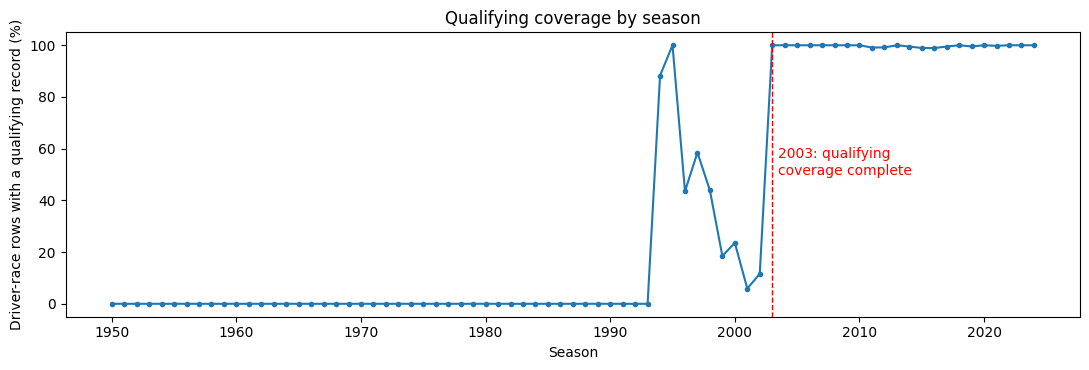

race_year
,1994    0.883
,1995    1.000
,1996    0.435
,1997    0.585
,1998    0.438
,1999    0.185
,2000    0.236
,2001    0.059
,2002    0.116
,2003    1.000
,2004    1.000


In [4]:
quali_cover = (
    base.assign(has_quali=base["quali_pos"].notna())
    .groupby("race_year")["has_quali"].mean()
)

plt.figure(figsize=(11, 3.8))
plt.plot(quali_cover.index, quali_cover.values * 100, marker="o", markersize=3)
plt.axvline(2003, color="red", linestyle="--", linewidth=1)
plt.text(2003.5, 50, "2003: qualifying\ncoverage complete", color="red")
plt.ylabel("Driver-race rows with a qualifying record (%)")
plt.xlabel("Season")
plt.title("Qualifying coverage by season")
save_fig("07_qualifying_coverage.png")

print(quali_cover.loc[1994:2004].round(3).to_string())

There is no qualifying data at all before 1994, and between 1996 and 2002 only part of the field has a record (as low as 6% in 2001). From **2003** onwards practically every driver has one. So anything that needs qualifying position is only reliable from 2003.

## 3. Q1 — Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

**Tables joined:** `results` (grid and finishing position) ← `races` (season, circuit) ← `circuits` (name), plus `qualifying` (qualifying position).

**Grain:** one row per driver per race. The "front-row starters" at a circuit are the driver-race rows with grid position 1 or 2, so each race normally contributes two rows.

**Qualifying vs grid:** these are not the same thing. Qualifying position is where the driver qualified. Grid (`results.grid`) is where they actually started after penalties, sprint results or pit-lane starts. We use the **grid** as the main definition because the question is about converting a *start*, and we also report the qualifying version.

**Window:** 2003–2013 (pre-hybrid) vs 2014–2024 (hybrid). That gives 11 seasons on each side, and 2003 is when qualifying coverage becomes complete, so both definitions can be compared on the same races.

In [5]:
q1 = base[base["race_year"].between(2003, 2024)].copy()
q1["era"] = np.where(q1["race_year"] >= 2014, "2014-2024", "2003-2013")
q1["front_row_grid"] = q1["grid"].isin([1, 2])
q1["front_row_quali"] = q1["quali_pos"].isin([1, 2])

mismatch = (
    q1.groupby(["front_row_quali", "front_row_grid"])
    .agg(entries=("podium", "size"), podium_rate=("podium", "mean"))
    .reset_index()
)
print(mismatch.round(3).to_string(index=False))

lost_front_row = q1[q1["front_row_quali"] & ~q1["front_row_grid"]]
print("\nQualified on the front row but did not start there:", len(lost_front_row))
lost_front_row[["race_year", "race_name", "driverId", "quali_pos", "grid", "positionOrder"]].sort_values("race_year").head(10)

 front_row_quali  front_row_grid  entries  podium_rate
,           False           False     8078        0.081
,           False            True       36        0.639
,            True           False       38        0.289
,            True            True      818        0.726
,
,Qualified on the front row but did not start there: 38


,race_year,race_name,driverId,quali_pos,grid,positionOrder
1965,2004,Monaco Grand Prix,23,2.0,12,10
1676,2005,British Grand Prix,8,2.0,12,3
1755,2005,Italian Grand Prix,8,1.0,11,4
931,2007,Hungarian Grand Prix,4,1.0,6,4
8070,2010,Canadian Grand Prix,17,2.0,7,5
21072,2011,Indian Grand Prix,1,2.0,5,7
21192,2012,Chinese Grand Prix,1,2.0,7,3
21240,2012,Spanish Grand Prix,1,1.0,24,8
21274,2012,Monaco Grand Prix,30,1.0,6,19
22899,2016,Russian Grand Prix,20,2.0,7,20


Front-row conversion is computed per circuit and era. A circuit needs at least 5 races in an era to be ranked. With fewer races one lucky or unlucky weekend swings the rate by 10–20 points. We also attach a Wilson 95% interval because the samples per circuit are small (10–22 front-row starts).

In [6]:
def front_row_conversion(df, flag_col, min_races=5):
    out = (
        df[df[flag_col]]
        .groupby(["circuit_name", "era"])
        .agg(races=("raceId", "nunique"), front_row_starts=("podium", "size"), podiums=("podium", "sum"))
        .reset_index()
    )
    out["conversion"] = out["podiums"] / out["front_row_starts"]
    out["ci_low"], out["ci_high"] = wilson_interval(out["podiums"], out["front_row_starts"])
    return out[out["races"] >= min_races]


conv_grid = front_row_conversion(q1, "front_row_grid")
conv_quali = front_row_conversion(q1, "front_row_quali")

overall = q1.groupby("era").apply(lambda d: pd.Series({
    "races": d["raceId"].nunique(),
    "grid_front_row_conversion": d.loc[d["front_row_grid"], "podium"].mean(),
    "quali_front_row_conversion": d.loc[d["front_row_quali"], "podium"].mean(),
}))
print(overall.round(3))

for era in ["2003-2013", "2014-2024"]:
    print(f"\nTop 10 circuits by front-row (grid) conversion, {era}")
    top = conv_grid[conv_grid["era"] == era].sort_values(["conversion", "front_row_starts"], ascending=False).head(10)
    print(top[["circuit_name", "races", "front_row_starts", "podiums", "conversion", "ci_low", "ci_high"]]
          .round(3).to_string(index=False))

           races  grid_front_row_conversion  quali_front_row_conversion
,era                                                                    
,2003-2013  200.0                       0.68                       0.672
,2014-2024  228.0                       0.76                       0.737
,
,Top 10 circuits by front-row (grid) conversion, 2003-2013
,                  circuit_name  races  front_row_starts  podiums  conversion  ci_low  ci_high
, Circuit de Nevers Magny-Cours      6                12       11       0.917   0.646    0.985
,                 Istanbul Park      7                14       11       0.786   0.524    0.924
,  Autodromo Nazionale di Monza     11                22       17       0.773   0.566    0.899
,             Circuit de Monaco     11                22       17       0.773   0.566    0.899
,           Silverstone Circuit     11                22       16       0.727   0.518    0.868
,  Circuit de Spa-Francorchamps      9                18       13       0.722 

In [7]:
wide = conv_grid.pivot(index="circuit_name", columns="era", values="conversion").dropna()
wide["rank_pre"] = wide["2003-2013"].rank(ascending=False, method="min")
wide["rank_hybrid"] = wide["2014-2024"].rank(ascending=False, method="min")
wide["change"] = wide["2014-2024"] - wide["2003-2013"]
rho, p_rho = stats.spearmanr(wide["2003-2013"], wide["2014-2024"])
print(f"Circuits with >= 5 races in both eras: {len(wide)}")
print(f"Spearman rank correlation between eras: {rho:.2f} (p = {p_rho:.3f})")
wide.sort_values("change").round(3)

Circuits with >= 5 races in both eras: 14
,Spearman rank correlation between eras: 0.30 (p = 0.292)


era,2003-2013,2014-2024,rank_pre,rank_hybrid,change
circuit_name,,,,,
Autodromo Nazionale di Monza,0.773,0.727,1.0,10.0,-0.045
Hungaroring,0.636,0.591,9.0,14.0,-0.045
Bahrain International Circuit,0.667,0.667,7.0,13.0,0.000
Silverstone Circuit,0.727,0.750,3.0,9.0,0.023
Circuit de Monaco,0.773,0.850,1.0,3.0,0.077
Circuit de Spa-Francorchamps,0.722,0.818,4.0,4.0,0.096
Albert Park Grand Prix Circuit,0.591,0.722,12.0,11.0,0.131
Shanghai International Circuit,0.650,0.786,8.0,7.0,0.136
Circuit de Barcelona-Catalunya,0.682,0.818,6.0,4.0,0.136


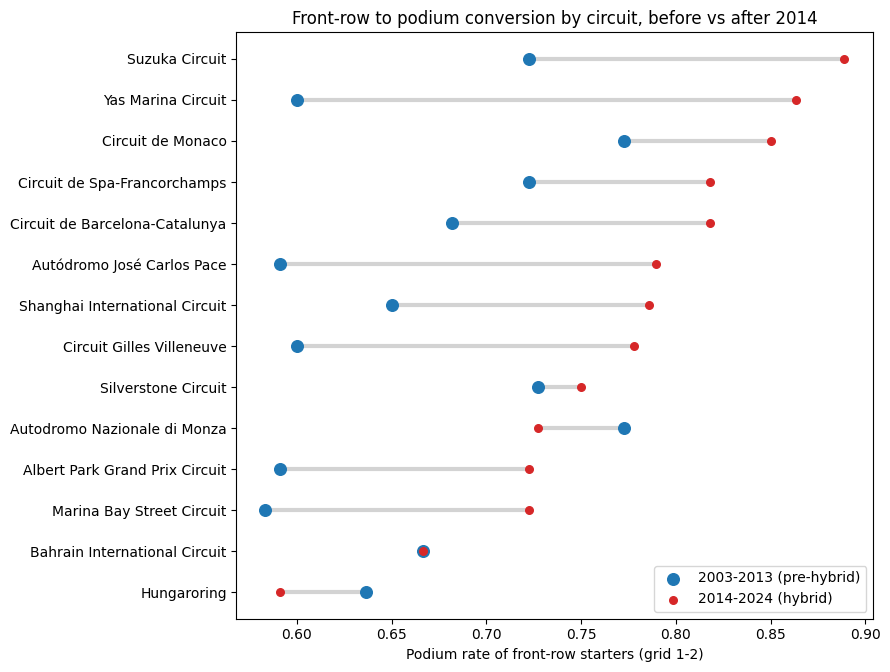

In [8]:
plot_df = wide.sort_values("2014-2024")
y = np.arange(len(plot_df))

plt.figure(figsize=(9, 0.38 * len(plot_df) + 1.5))
plt.hlines(y, plot_df["2003-2013"], plot_df["2014-2024"], color="lightgrey", linewidth=3)
plt.scatter(plot_df["2003-2013"], y, label="2003-2013 (pre-hybrid)", color="tab:blue", s=70, zorder=3)
plt.scatter(plot_df["2014-2024"], y, label="2014-2024 (hybrid)", color="tab:red", s=30, zorder=4)
plt.yticks(y, plot_df.index)
plt.xlabel("Podium rate of front-row starters (grid 1-2)")
plt.title("Front-row to podium conversion by circuit, before vs after 2014")
plt.legend(loc="lower right")
save_fig("08_q1_front_row_conversion_dumbbell.png")

Next we check whether using qualifying position instead of the grid changes the answer.

Circuit-eras where the qualifying definition gives a different conversion rate:
,                  circuit_name       era  conversion_grid  conversion_quali   diff
,    Autódromo José Carlos Pace 2014-2024            0.789             0.650 -0.139
,             Circuit de Monaco 2003-2013            0.773             0.682 -0.091
,     Circuit Gilles Villeneuve 2014-2024            0.778             0.722 -0.056
,  Autódromo Hermanos Rodríguez 2014-2024            0.611             0.556 -0.056
,       Circuit of the Americas 2014-2024            0.800             0.750 -0.050
,  Autodromo Nazionale di Monza 2003-2013            0.773             0.727 -0.045
,Circuit de Barcelona-Catalunya 2003-2013            0.682             0.636 -0.045
,                   Hungaroring 2003-2013            0.636             0.591 -0.045
,            Yas Marina Circuit 2014-2024            0.864             0.818 -0.045
,                 Red Bull Ring 2014-2024            0.731             0.692 -0.

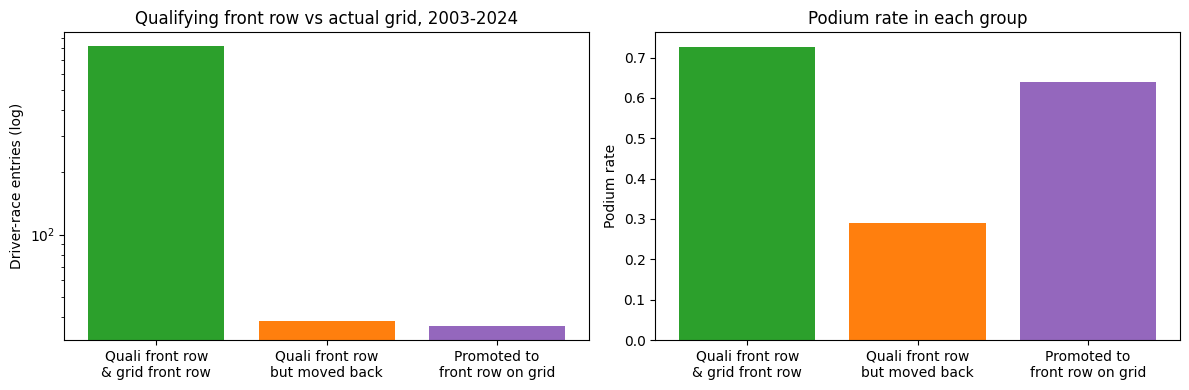

In [9]:
compare_def = conv_grid.merge(conv_quali, on=["circuit_name", "era"], suffixes=("_grid", "_quali"))
compare_def["diff"] = compare_def["conversion_quali"] - compare_def["conversion_grid"]
print("Circuit-eras where the qualifying definition gives a different conversion rate:")
print(compare_def.loc[compare_def["diff"] != 0, ["circuit_name", "era", "conversion_grid", "conversion_quali", "diff"]]
      .sort_values("diff").round(3).to_string(index=False))

groups = {
    "Quali front row\n& grid front row": q1["front_row_quali"] & q1["front_row_grid"],
    "Quali front row\nbut moved back": q1["front_row_quali"] & ~q1["front_row_grid"],
    "Promoted to\nfront row on grid": ~q1["front_row_quali"] & q1["front_row_grid"],
}
counts = [int(mask.sum()) for mask in groups.values()]
rates = [q1.loc[mask, "podium"].mean() for mask in groups.values()]
bar_colors = ["tab:green", "tab:orange", "tab:purple"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(groups.keys(), counts, color=bar_colors)
axes[0].set_yscale("log")
axes[0].set_ylabel("Driver-race entries (log)")
axes[0].set_title("Qualifying front row vs actual grid, 2003-2024")
axes[1].bar(groups.keys(), rates, color=bar_colors)
axes[1].set_ylabel("Podium rate")
axes[1].set_title("Podium rate in each group")
save_fig("09_q1_quali_vs_grid.png")

As a robustness check we use the grid definition only (it is available for every season) and compare all of 1950–2013 against the hybrid era.

In [10]:
long_history = base.copy()
long_history["era"] = np.where(long_history["race_year"] >= 2014, "2014-2024", "1950-2013")
long_history["front_row_grid"] = long_history["grid"].isin([1, 2])
long_conv = front_row_conversion(long_history, "front_row_grid")
long_wide = long_conv.pivot(index="circuit_name", columns="era", values="conversion").dropna()
rho_long, p_long = stats.spearmanr(long_wide["1950-2013"], long_wide["2014-2024"])
print(f"Grid only, 1950-2013 vs 2014-2024: {len(long_wide)} circuits, Spearman = {rho_long:.2f} (p = {p_long:.3f})")

q1_out = conv_grid.merge(
    conv_quali[["circuit_name", "era", "front_row_starts", "podiums", "conversion"]],
    on=["circuit_name", "era"], how="left", suffixes=("_grid", "_quali"),
)
q1_out.to_csv(REPORT_DIR / "member2_q1_front_row_conversion.csv", index=False)

Grid only, 1950-2013 vs 2014-2024: 16 circuits, Spearman = -0.03 (p = 0.909)


### Q1 answer

- Starting from the front row became more valuable overall: 68.0% of front-row starters finished on the podium in 2003–2013, against 76.0% in 2014–2024. This fits the long spells of one dominant team in the hybrid era.
- **Pre-hybrid (2003–2013) top converters:** Magny-Cours (11/12, 91.7%), Istanbul Park (78.6%), Monza and Monaco (77.3%).
- **Hybrid (2014–2024) top converters:** Suzuka (16/18, 88.9%), Yas Marina (86.4%), Monaco (85.0%), Barcelona and Spa (81.8%).
- **The ranking does change.** For the 14 circuits with at least 5 races in both eras, the rank correlation between eras is only 0.30 (p = 0.29). Monza fell from 1st to 10th of 14, Yas Marina jumped from 10th to 2nd, and Hungary sits last in the hybrid era (59%). Over the longer 1950–2013 vs 2014–2024 comparison the correlation is about zero (−0.03). Circuit "front-row reliability" is therefore not a stable property, and it should not be used as a fixed feature.
- **Qualifying ≠ grid.** 38 drivers qualified on the front row but started further back (penalties, pit-lane starts) and only 28.9% of them reached the podium. 36 drivers were promoted onto the front row and 63.9% of them did. At individual circuits the two definitions can differ a lot, for example Interlagos 2014–2024 is 78.9% by grid but 65.0% by qualifying. The grid is the more honest definition of a "front-row start".

**Missingness:** qualifying position is missing for only a handful of rows from 2003, so both definitions use the same races. Circuits with fewer than 5 races in an era are not ranked.
**Cutoff:** both grid and qualifying position are known before the race, so the conditioning variable respects the cutoff. Only the outcome (podium) is post-race, which is what we are measuring.

## 4. Q2 — Do drivers podium more often at circuits in their home country?

**Tables joined:** `results` ← `drivers` (nationality) and `results` ← `races` ← `circuits` (country).

**Grain:** one row per driver per race, labelled `home = True` when the circuit's country matches the driver's nationality.

Nationality is stored as a demonym ("British", "Monegasque") and the circuit country as a name ("UK", "Monaco"), so we map one to the other. Drivers listed with a double nationality (e.g. "American-Italian") count as home in both countries. "United States" and "USA" are merged into one country.

In [11]:
NATIONALITY_TO_COUNTRIES = {
    "American": {"USA"}, "American-Italian": {"USA", "Italy"}, "Argentine": {"Argentina"},
    "Argentine-Italian": {"Argentina", "Italy"}, "Argentinian": {"Argentina"}, "Australian": {"Australia"},
    "Austrian": {"Austria"}, "Belgian": {"Belgium"}, "Brazilian": {"Brazil"}, "British": {"UK"},
    "Canadian": {"Canada"}, "Chilean": {"Chile"}, "Chinese": {"China"}, "Colombian": {"Colombia"},
    "Czech": {"Czech Republic"}, "Danish": {"Denmark"}, "Dutch": {"Netherlands"}, "East German": {"Germany"},
    "Finnish": {"Finland"}, "French": {"France"}, "German": {"Germany"}, "Hungarian": {"Hungary"},
    "Indian": {"India"}, "Indonesian": {"Indonesia"}, "Irish": {"Ireland"}, "Italian": {"Italy"},
    "Japanese": {"Japan"}, "Liechtensteiner": {"Liechtenstein"}, "Malaysian": {"Malaysia"},
    "Mexican": {"Mexico"}, "Monegasque": {"Monaco"}, "New Zealander": {"New Zealand"}, "Polish": {"Poland"},
    "Portuguese": {"Portugal"}, "Rhodesian": {"Zimbabwe"}, "Russian": {"Russia"},
    "South African": {"South Africa"}, "Spanish": {"Spain"}, "Swedish": {"Sweden"}, "Swiss": {"Switzerland"},
    "Thai": {"Thailand"}, "Uruguayan": {"Uruguay"}, "Venezuelan": {"Venezuela"},
}

drivers["nationality"] = drivers["nationality"].str.strip()
unmapped = set(drivers["nationality"].dropna()) - set(NATIONALITY_TO_COUNTRIES)
assert not unmapped, unmapped


def is_home(nationality, country):
    if pd.isna(nationality) or pd.isna(country):
        return False
    return country in NATIONALITY_TO_COUNTRIES[nationality]


q2 = base.merge(drivers[["driverId", "nationality"]], on="driverId", how="left", validate="many_to_one")
q2["circuit_country"] = q2["circuit_country"].replace({"United States": "USA"})
q2["home"] = [is_home(n, c) for n, c in zip(q2["nationality"], q2["circuit_country"])]
print("Circuit countries:", sorted(q2["circuit_country"].unique()))

indy = q2["race_name"].eq("Indianapolis 500")
print("\nIndianapolis 500 rows:", int(indy.sum()), "| share of them that are 'home':", round(q2.loc[indy, "home"].mean(), 3))
print("Home share in all other races:", round(q2.loc[~indy, "home"].mean(), 3))

Circuit countries: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA']
,
,Indianapolis 500 rows: 381 | share of them that are 'home': 0.997
,Home share in all other races: 0.08


**Indianapolis 500 (1950–1960):** it counted for the championship, but it was a separate event run almost entirely by American oval specialists. 99.7% of its rows are "home" rows, compared with 8% everywhere else. It has nothing to do with home advantage in Grand Prix racing, so we exclude it from the main analysis and report the result with it included as a sensitivity check.

**Controlling for starting position:** we split the grid into bands (P1, P2, P3, P4–5, P6–8, P9–12, P13+) and only compare home and away drivers *inside the same band*. The bands are narrow at the front because that is where the podium probability changes fastest. Rows with grid 0 (pit-lane start, or unknown grid in early seasons) cannot be placed in a band, so they are left out.

In [12]:
GRID_BINS = [0, 1, 2, 3, 5, 8, 12, 100]
GRID_LABELS = ["P1", "P2", "P3", "P4-5", "P6-8", "P9-12", "P13+"]

q2_main = q2[~indy & (q2["grid"] >= 1)].copy()
q2_main["grid_band"] = pd.cut(q2_main["grid"], bins=GRID_BINS, labels=GRID_LABELS)
print("Rows used:", len(q2_main), "| left out for grid = 0:", int((~indy & (q2["grid"] == 0)).sum()))

raw = q2_main.groupby("home")["podium"].agg(starts="size", podium_rate="mean")
print("\nUnadjusted podium rate:")
print(raw.round(4))
median_grid = q2_main.groupby("home")["grid"].median()
print("\nMedian grid slot - home:", median_grid[True], "| away:", median_grid[False])

strata = (
    q2_main.groupby(["grid_band", "home"], observed=True)["podium"]
    .agg(starts="size", podiums="sum")
    .unstack("home")
)
strata.columns = [f"{stat}_{'home' if is_home_col else 'away'}" for stat, is_home_col in strata.columns]
strata["rate_home"] = strata["podiums_home"] / strata["starts_home"]
strata["rate_away"] = strata["podiums_away"] / strata["starts_away"]
strata["difference"] = strata["rate_home"] - strata["rate_away"]
strata.round(3)

Rows used: 24652 | left out for grid = 0: 1635
,
,Unadjusted podium rate:
,       starts  podium_rate
,home                      
,False   22708       0.1378
,True     1944       0.1183
,
,Median grid slot - home: 13.0 | away: 11.0


,starts_away,starts_home,podiums_away,podiums_home,rate_home,rate_away,difference
grid_band,,,,,,,
P1,1032,81,668,49,0.605,0.647,-0.042
P2,1032,75,580,42,0.560,0.562,-0.002
P3,1042,73,477,40,0.548,0.458,0.090
P4-5,2082,144,615,50,0.347,0.295,0.052
P6-8,3100,237,435,28,0.118,0.140,-0.022
P9-12,4115,347,223,18,0.052,0.054,-0.002
P13+,10305,987,131,3,0.003,0.013,-0.010


To summarise all bands in a single number we use the **Mantel–Haenszel odds ratio**, which is the standard way to combine several 2×2 tables (home/away × podium/no podium) while holding the stratifying variable fixed. A value of 1 means no home effect. For the 95% interval we bootstrap whole races (2000 resamples), because drivers in the same race are not independent of each other. Only three of them can finish on the podium.

We also compute the number of podiums home drivers *would* have scored if they converted at the away rate of their own grid band.

In [13]:
def race_tables(df):
    cells = pd.DataFrame({
        "raceId": df["raceId"],
        "grid_band": df["grid_band"],
        "a": df["home"] & df["podium"].eq(1),
        "b": df["home"] & df["podium"].eq(0),
        "c": ~df["home"] & df["podium"].eq(1),
        "d": ~df["home"] & df["podium"].eq(0),
    })
    per_race = cells.groupby(["raceId", "grid_band"], observed=True)[["a", "b", "c", "d"]].sum()
    per_race = per_race.unstack("grid_band", fill_value=0)
    per_race = per_race.reindex(columns=pd.MultiIndex.from_product([["a", "b", "c", "d"], GRID_LABELS]), fill_value=0)
    return per_race.to_numpy().reshape(len(per_race), 4, len(GRID_LABELS)).transpose(0, 2, 1)


def mh_from_tables(tables):
    a, b, c, d = tables.sum(axis=0).T
    n = a + b + c + d
    keep = n > 0
    return (a[keep] * d[keep] / n[keep]).sum() / (b[keep] * c[keep] / n[keep]).sum()


def mantel_haenszel(df, n_boot=2000, seed=42):
    tables = race_tables(df)
    rng = np.random.default_rng(seed)
    boot = [mh_from_tables(tables[rng.integers(0, len(tables), len(tables))]) for _ in range(n_boot)]
    low, high = np.percentile(boot, [2.5, 97.5])
    return mh_from_tables(tables), low, high


mh_or, ci_low, ci_high = mantel_haenszel(q2_main)
expected_home = (strata["starts_home"] * strata["rate_away"]).sum()
observed_home = strata["podiums_home"].sum()

print(f"Mantel-Haenszel odds ratio (home vs away, within grid bands): {mh_or:.2f}  95% CI [{ci_low:.2f}, {ci_high:.2f}]")
print(f"Home podiums observed: {observed_home:.0f} | expected at away rates for the same grid bands: {expected_home:.1f}")

Mantel-Haenszel odds ratio (home vs away, within grid bands): 0.97  95% CI [0.81, 1.14]
,Home podiums observed: 230 | expected at away rates for the same grid bands: 235.1


The same test by period, and with the Indianapolis 500 put back in:

In [14]:
q2_main["period"] = pd.cut(q2_main["race_year"], [1949, 1979, 2002, 2024], labels=["1950-1979", "1980-2002", "2003-2024"])
with_indy = q2[q2["grid"] >= 1].copy()
with_indy["grid_band"] = pd.cut(with_indy["grid"], bins=GRID_BINS, labels=GRID_LABELS)

subsets = [(str(period), grp) for period, grp in q2_main.groupby("period", observed=True)]
subsets += [("All, Indy 500 excluded", q2_main), ("All, Indy 500 included", with_indy)]

by_period = []
for label, grp in subsets:
    est, lo, hi = mantel_haenszel(grp)
    by_period.append({"subset": label, "home_starts": int(grp["home"].sum()),
                      "mh_odds_ratio": est, "ci_low": lo, "ci_high": hi})
by_period = pd.DataFrame(by_period)
print(by_period.round(3).to_string(index=False))

                subset  home_starts  mh_odds_ratio  ci_low  ci_high
,             1950-1979          899          0.967   0.730    1.254
,             1980-2002          681          1.009   0.757    1.288
,             2003-2024          364          0.758   0.516    1.099
,All, Indy 500 excluded         1944          0.966   0.811    1.144
,All, Indy 500 included         2324          0.965   0.839    1.119


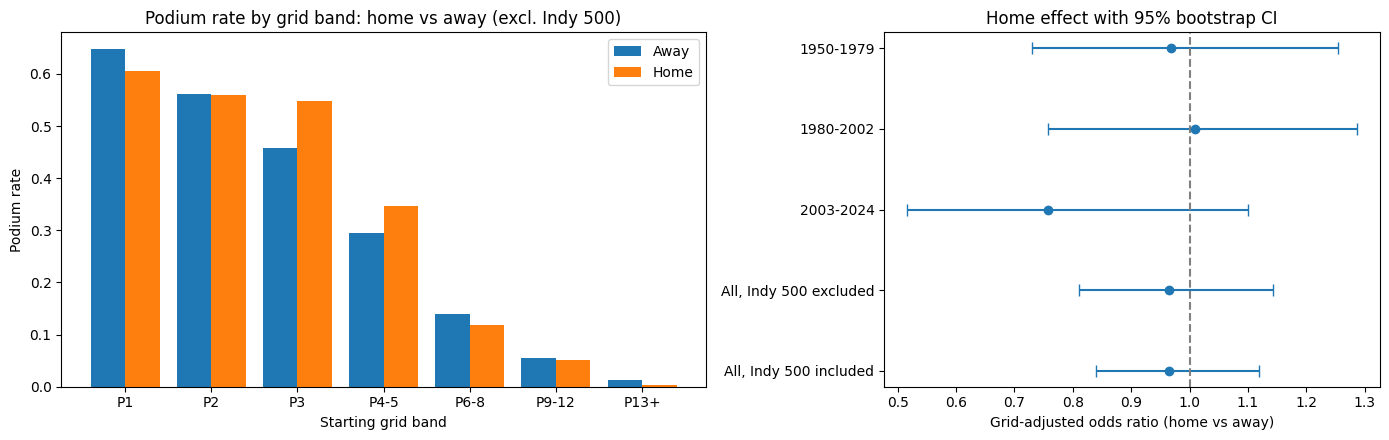

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
x = np.arange(len(strata))
axes[0].bar(x - 0.2, strata["rate_away"], 0.4, label="Away")
axes[0].bar(x + 0.2, strata["rate_home"], 0.4, label="Home")
axes[0].set_xticks(x, strata.index)
axes[0].set_xlabel("Starting grid band")
axes[0].set_ylabel("Podium rate")
axes[0].set_title("Podium rate by grid band: home vs away (excl. Indy 500)")
axes[0].legend()

yy = np.arange(len(by_period))[::-1]
axes[1].errorbar(by_period["mh_odds_ratio"], yy,
                 xerr=[by_period["mh_odds_ratio"] - by_period["ci_low"], by_period["ci_high"] - by_period["mh_odds_ratio"]],
                 fmt="o", capsize=4)
axes[1].axvline(1, color="grey", linestyle="--")
axes[1].set_yticks(yy, by_period["subset"])
axes[1].set_xlabel("Grid-adjusted odds ratio (home vs away)")
axes[1].set_title("Home effect with 95% bootstrap CI")
save_fig("10_q2_home_advantage.png")

strata.to_csv(REPORT_DIR / "member2_q2_home_by_grid_band.csv")
by_period.to_csv(REPORT_DIR / "member2_q2_home_odds_ratio.csv", index=False)

### Q2 answer

**No, we find no evidence of a home podium advantage once starting position is controlled for.**

- Without any adjustment, home drivers actually podium *less* often (11.8% vs 13.8%). They also start further back (median grid 13 vs 11), because home races attract one-off local entries and weaker local drivers. Comparing raw rates would be misleading.
- Within each grid band the home–away differences are small and change sign (home is better from P3 and P4–5, worse from P1 and P6–8).
- The grid-adjusted Mantel–Haenszel odds ratio is about 0.97, with a bootstrap 95% interval that comfortably contains 1. Home drivers scored 230 podiums against roughly 235 expected from their grid bands.
- The conclusion holds in every period and whether or not the Indianapolis 500 is included. Every interval contains 1.

**Grain:** driver-race rows. **Missingness:** 1,635 rows with grid 0 are left out because they cannot be placed in a grid band, and nationality and circuit country are complete. **Cutoff:** the home flag and grid are both known before the race. This result is also why `home_race` is *not* kept as a model feature (see Section 6).

## 5. Q3 — Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Tables joined:** `results` ← `status` (reason the race ended) ← `constructors` (team name) and `results` ← `races` (season).

**Grain:** one row per driver per race *start*, aggregated to constructor × period.

**Definition:** a mechanical retirement is a start that ended because a car component failed. We go through the `status` table and split it into three lists:

- **Mechanical:** engine, power unit, ERS, gearbox, hydraulics, brakes, suspension, electrical, cooling, fuel system and similar component failures.
- **Ambiguous:** `Retired` (no reason given), `Wheel`/`Wheel nut` (often a pit-stop error), tyres and punctures (usually debris or contact), wings and undertray (usually crash damage), `Out of fuel` (a team mistake).
- **Not mechanical:** accidents, collisions, collision damage, spins, disqualifications, illness and so on.

The main answer uses the strict mechanical list. The ambiguous list is added only in a sensitivity check.

**Denominator:** race starts. Withdrawn (`W`) and did-not-qualify (`F`) entries never started the race, so they are removed. This includes a few cars that broke down before the start, since by the question's definition they are not retirements from a race start.

In [16]:
MECHANICAL = [
    "Engine", "Gearbox", "Transmission", "Clutch", "Hydraulics", "Electrical", "Radiator", "Suspension",
    "Brakes", "Differential", "Overheating", "Mechanical", "Driveshaft", "Fuel pressure", "Water pressure",
    "Throttle", "Steering", "Technical", "Electronics", "Heat shield fire", "Exhaust", "Oil leak", "Wheel rim",
    "Water leak", "Fuel pump", "Track rod", "Oil pressure", "Engine fire", "Engine misfire", "Pneumatics",
    "Fuel system", "Oil line", "Fuel", "Power loss", "Vibrations", "Drivetrain", "Ignition", "Chassis",
    "Battery", "Halfshaft", "Crankshaft", "Alternator", "Oil pump", "Fuel leak", "Injection", "Distributor",
    "Turbo", "CV joint", "Water pump", "Spark plugs", "Fuel pipe", "Oil pipe", "Axle", "Water pipe", "Magneto",
    "Supercharger", "Power Unit", "ERS", "Brake duct", "Cooling system", "Wheel bearing", "Launch control",
]
AMBIGUOUS = ["Retired", "Wheel", "Wheel nut", "Tyre", "Puncture", "Tyre puncture", "Front wing", "Rear wing",
             "Broken wing", "Undertray", "Out of fuel", "Seat", "Driver Seat", "Safety belt", "Handling", "Stalled"]
NOT_STARTED = ["Did not qualify", "Did not prequalify", "107% Rule", "Withdrew"]

assert set(MECHANICAL).issubset(status["status"])
assert set(AMBIGUOUS).issubset(status["status"])

q3 = base[base["race_year"].between(2014, 2024)].copy()
q3["period"] = np.where(q3["race_year"] <= 2021, "2014-2021", "2022-2024")
q3["started"] = ~q3["positionText"].isin(["W", "F"]) & ~q3["status"].isin(NOT_STARTED)
q3["mechanical"] = q3["status"].isin(MECHANICAL)
q3["mechanical_broad"] = q3["status"].isin(MECHANICAL + AMBIGUOUS)

print("Entries 2014-2024:", len(q3), "| non-starts removed:", int((~q3["started"]).sum()))
print("Non-starts by status:", q3.loc[~q3["started"], "status"].value_counts().to_dict())
q3 = q3[q3["started"]]

classified = q3["status"].str.match(r"^(Finished|\+\d+ Laps?)$")
print("\nMechanical retirements (strict):", int(q3["mechanical"].sum()))
print("Ambiguous retirements:", q3.loc[q3["status"].isin(AMBIGUOUS), "status"].value_counts().to_dict())
print("Retirements counted as NOT mechanical:", q3.loc[~q3["mechanical_broad"] & ~classified, "status"].value_counts().to_dict())

Entries 2014-2024: 4626 | non-starts removed: 31
,Non-starts by status: {'Withdrew': 14, 'Power Unit': 3, 'Gearbox': 2, 'Engine': 2, 'Fuel system': 1, 'ERS': 1, 'Power loss': 1, 'Retired': 1, 'Hydraulics': 1, 'Exhaust': 1, 'Driveshaft': 1, 'Brakes': 1, 'Illness': 1, 'Fuel leak': 1}
,
,Mechanical retirements (strict): 362
,Ambiguous retirements: {'Retired': 49, 'Wheel': 11, 'Puncture': 7, 'Tyre': 4, 'Undertray': 4, 'Rear wing': 3, 'Front wing': 3, 'Wheel nut': 3, 'Seat': 1, 'Out of fuel': 1}
,Retirements counted as NOT mechanical: {'Collision': 150, 'Accident': 85, 'Collision damage': 59, 'Disqualified': 11, 'Spun off': 11, 'Damage': 2, 'Illness': 2, 'Excluded': 1, 'Debris': 1}


A constructor needs at least 40 starts in a period, which is about one full season with two cars, to be ranked. This only removes Caterham and Marussia (2014 only) from the first period.

In [17]:
MIN_STARTS = 40

rates = (
    q3.groupby(["period", "constructor_name"])
    .agg(starts=("raceId", "size"), mech_dnf=("mechanical", "sum"), mech_dnf_broad=("mechanical_broad", "sum"))
    .reset_index()
)
rates["mech_rate"] = rates["mech_dnf"] / rates["starts"]
rates["mech_rate_broad"] = rates["mech_dnf_broad"] / rates["starts"]
rates["ci_low"], rates["ci_high"] = wilson_interval(rates["mech_dnf"], rates["starts"])
print("Not ranked (fewer than", MIN_STARTS, "starts):",
      rates.loc[rates["starts"] < MIN_STARTS, ["period", "constructor_name", "starts"]].to_dict("records"))
rates = rates[rates["starts"] >= MIN_STARTS]

for period in ["2014-2021", "2022-2024"]:
    print(f"\n{period}")
    print(rates[rates["period"] == period].sort_values("mech_rate", ascending=False)
          [["constructor_name", "starts", "mech_dnf", "mech_rate", "ci_low", "ci_high", "mech_rate_broad"]]
          .round(3).to_string(index=False))

print()
for period in ["2014-2021", "2022-2024"]:
    sub = rates[rates["period"] == period]
    r_s = stats.spearmanr(sub["mech_rate"], sub["mech_rate_broad"])[0]
    print(f"{period}: rank correlation between strict and broad definition = {r_s:.2f}")

Not ranked (fewer than 40 starts): [{'period': '2014-2021', 'constructor_name': 'Caterham', 'starts': 33}, {'period': '2014-2021', 'constructor_name': 'Marussia', 'starts': 31}]
,
,2014-2021
,constructor_name  starts  mech_dnf  mech_rate  ci_low  ci_high  mech_rate_broad
,        Lotus F1      75        13      0.173   0.104    0.274            0.240
,      Toro Rosso     242        39      0.161   0.120    0.213            0.182
,         Renault     199        26      0.131   0.091    0.185            0.156
,         McLaren     315        41      0.130   0.097    0.172            0.152
,        Red Bull     318        34      0.107   0.078    0.146            0.116
,          Sauber     199        21      0.106   0.070    0.156            0.131
,      AlphaTauri      77         7      0.091   0.045    0.176            0.104
,    Racing Point      75         6      0.080   0.037    0.164            0.093
,    Haas F1 Team     240        18      0.075   0.048    0.115            0.121

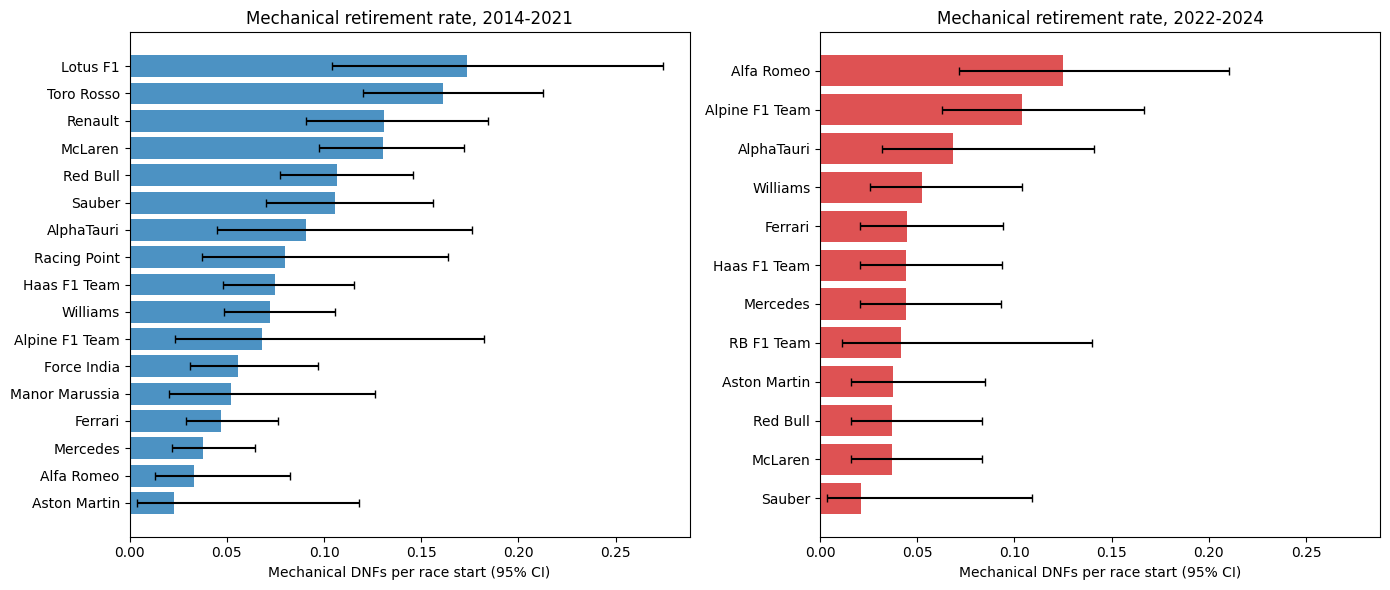

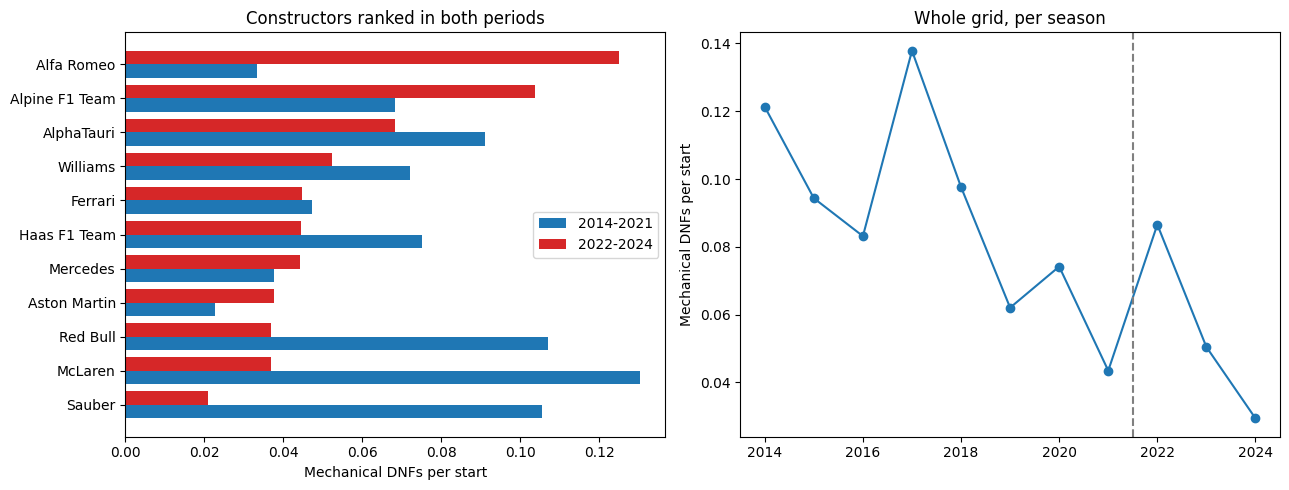

race_year
,2014    0.121
,2015    0.094
,2016    0.083
,2017    0.138
,2018    0.098
,2019    0.062
,2020    0.074
,2021    0.043
,2022    0.087
,2023    0.050
,2024    0.029


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True)
for ax, period, color in zip(axes, ["2014-2021", "2022-2024"], ["tab:blue", "tab:red"]):
    sub = rates[rates["period"] == period].sort_values("mech_rate")
    ax.barh(sub["constructor_name"], sub["mech_rate"],
            xerr=[sub["mech_rate"] - sub["ci_low"], sub["ci_high"] - sub["mech_rate"]],
            color=color, alpha=0.8, capsize=3)
    ax.set_title(f"Mechanical retirement rate, {period}")
    ax.set_xlabel("Mechanical DNFs per race start (95% CI)")
save_fig("11_q3_mechanical_retirement_rates.png")

both = rates.pivot(index="constructor_name", columns="period", values="mech_rate").dropna()
yearly = q3.groupby("race_year")["mechanical"].mean()

both = both.sort_values("2022-2024")
yb = np.arange(len(both))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(yb - 0.2, both["2014-2021"], 0.4, label="2014-2021", color="tab:blue")
axes[0].barh(yb + 0.2, both["2022-2024"], 0.4, label="2022-2024", color="tab:red")
axes[0].set_yticks(yb, both.index)
axes[0].set_xlabel("Mechanical DNFs per start")
axes[0].set_title("Constructors ranked in both periods")
axes[0].legend(loc="center right")
axes[1].plot(yearly.index, yearly.values, marker="o")
axes[1].axvline(2021.5, color="grey", linestyle="--")
axes[1].set_ylabel("Mechanical DNFs per start")
axes[1].set_title("Whole grid, per season")
save_fig("12_q3_mechanical_trend.png")

print(yearly.round(3).to_string())
rates.to_csv(REPORT_DIR / "member2_q3_mechanical_retirement_rates.csv", index=False)

### Q3 answer

- **2014–2021:** the highest mechanical-retirement rates belong to **Lotus F1 (17.3% of starts)**, **Toro Rosso (16.1%)**, **Renault (13.1%)** and **McLaren (13.0%)**. The McLaren figure comes mostly from the McLaren-Honda years. Mercedes (3.8%), Ferrari (4.7%) and the Alfa Romeo / Aston Martin entries are at the bottom.
- **2022–2024:** **Alfa Romeo (12.5%)** and **Alpine (10.4%)** are clearly the least reliable. Behind them the field is tightly packed between 2% and 7%.
- Reliability improved a lot overall. The whole grid went from about 12% mechanical DNFs per start in 2014 to about 3% in 2024. The top teams converged to roughly 4% in the new ground-effect era.
- **Sensitivity:** adding the ambiguous statuses barely changes the 2014–2021 ranking (rank correlation 0.97). For 2022–2024 it changes more (0.68), mainly because RB and Sauber only have one season (48 starts), so two or three ambiguous retirements move them up a lot. The top two teams stay the same either way.

**Grain:** race starts aggregated to constructor × period. **Missingness:** status is never missing, but `Retired` gives no reason (counted only in the broad version). **Caveat:** constructors are kept as they appear in the data, so renamed teams (Toro Rosso → AlphaTauri → RB, Force India → Racing Point → Aston Martin, Sauber → Alfa Romeo → Sauber, Renault → Alpine) show up as separate rows. **Cutoff:** this question is descriptive (retirements are a race outcome). It does not produce a feature for the same race, but the *past* DNF rate is used as a form feature below.

## 6. Feature engineering

Every feature has to be computable for a race **before it starts**. We use three kinds of information:

- **Grid and qualifying:** known after qualifying, so allowed.
- **Form:** built only from races strictly *before* the current one (the `shift(1)` in every rolling feature).
- **Standings:** taken from the standings after the *previous round of the same season*, because the standings row for the current `raceId` already includes the current race.

### 6.1 Which rows enter the table

Races are ordered by season and round to get a running race number (`race_seq`). Entries that **did not qualify** are dropped, because at the cutoff we already know they will not start, so they are not real prediction cases. Withdrawn entries (`W`) are kept: some withdrawals happen on race morning, after the cutoff, and dropping them would use information we would not have.

In [19]:
race_order = races[["raceId", "year", "round"]].sort_values(["year", "round"]).reset_index(drop=True)
race_order["race_seq"] = np.arange(len(race_order))
race_order["prev_raceId"] = race_order.groupby("year")["raceId"].shift(1).astype("Int64")

DNQ_STATUS = ["Did not qualify", "Did not prequalify", "107% Rule"]
hist = base.merge(race_order[["raceId", "race_seq", "prev_raceId"]], on="raceId", how="left", validate="many_to_one")
hist["qualified"] = ~hist["positionText"].eq("F") & ~hist["status"].isin(DNQ_STATUS)
hist["finished"] = hist["status"].str.match(r"^(Finished|\+\d+ Laps?)$")
print("Entries:", len(hist), "| did not qualify (dropped):", int((~hist["qualified"]).sum()))
print("DNQ rows from 2003 on:", int((~hist["qualified"] & (hist["race_year"] >= 2003)).sum()))

hist = hist[hist["qualified"]].sort_values(["driverId", "race_seq"]).reset_index(drop=True)
hist["field_size"] = hist.groupby("raceId")["driverId"].transform("size")

Entries: 26668 | did not qualify (dropped): 1366
,DNQ rows from 2003 on: 4


Form is computed over the **full history (1950 onward)** even though the modeling table starts later. This way a driver in 2003 already has their form from 2002 instead of starting from nothing.

### 6.2 Experiment: how many past races should the form window use?

We try windows of 3, 5, 10 and 20 previous races for the two main driver-form features and measure how well each one separates podium from non-podium on its own (single-feature ROC-AUC). We only use seasons 2003–2018 here, so the later seasons stay untouched for Member 3's validation and test sets.

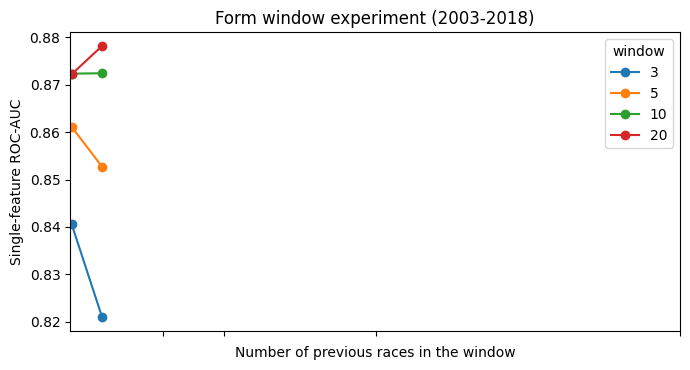

window,3,5,10,20
feature,,,,
driver_avg_finish,0.8406,0.8611,0.8723,0.8722
driver_podium_rate,0.8210,0.8527,0.8724,0.8782


In [20]:
def past_mean(df, keys, col, window):
    return df.groupby(keys)[col].transform(lambda s: s.shift(1).rolling(window, min_periods=1).mean())


window_trials = []
for w in [3, 5, 10, 20]:
    hist[f"try_podium_{w}"] = past_mean(hist, "driverId", "podium", w)
    hist[f"try_finish_{w}"] = past_mean(hist, "driverId", "positionOrder", w)

trial = hist[hist["race_year"].between(2003, 2018)]
for w in [3, 5, 10, 20]:
    for name in ["podium", "finish"]:
        col = f"try_{name}_{w}"
        ok = trial[col].notna()
        auc = roc_auc_score(trial.loc[ok, "podium"], trial.loc[ok, col])
        window_trials.append({"feature": f"driver_{name}_rate" if name == "podium" else "driver_avg_finish",
                              "window": w, "auc": max(auc, 1 - auc)})
window_trials = pd.DataFrame(window_trials).pivot(index="feature", columns="window", values="auc")
hist = hist.drop(columns=[c for c in hist.columns if c.startswith("try_")])

window_trials.plot(marker="o", figsize=(7, 3.8))
plt.xlabel("Number of previous races in the window")
plt.ylabel("Single-feature ROC-AUC")
plt.title("Form window experiment (2003-2018)")
plt.xticks([3, 5, 10, 20])
save_fig("13_fe_form_window_experiment.png")
window_trials.round(4)

Going from 3 to 10 races helps clearly (about +0.03 to +0.05 AUC). From 10 to 20 the average finish does not improve at all and the podium rate gains only ~0.006. A 20-race window covers almost a whole season, so after a team switch or a regulation change it would keep describing the old car for a year. We use **10 races** for all form features.

### 6.3 Form features

In [21]:
WINDOW = 10

hist["dnf"] = (~hist["finished"]).astype(int)
hist["drv_starts_before"] = hist.groupby("driverId").cumcount()
hist["drv_podium_rate_last10"] = past_mean(hist, "driverId", "podium", WINDOW)
hist["drv_avg_finish_last10"] = past_mean(hist, "driverId", "positionOrder", WINDOW)
hist["drv_dnf_rate_last10"] = past_mean(hist, "driverId", "dnf", WINDOW)

hist = hist.sort_values(["driverId", "circuitId", "race_seq"])
hist["drv_circuit_podiums_before"] = (
    hist.groupby(["driverId", "circuitId"])["podium"].transform(lambda s: s.shift(1).cumsum()).fillna(0)
)
hist = hist.sort_values(["driverId", "race_seq"]).reset_index(drop=True)

team_race = (
    hist.groupby(["constructorId", "raceId", "race_seq"], as_index=False)
    .agg(team_podiums=("podium", "sum"), team_cars=("podium", "size"), team_best=("positionOrder", "min"))
    .sort_values(["constructorId", "race_seq"])
    .reset_index(drop=True)
)
prev_podiums = team_race.groupby("constructorId")["team_podiums"].transform(lambda s: s.shift(1).rolling(WINDOW, min_periods=1).sum())
prev_cars = team_race.groupby("constructorId")["team_cars"].transform(lambda s: s.shift(1).rolling(WINDOW, min_periods=1).sum())
team_race["team_podium_rate_last10"] = prev_podiums / prev_cars
team_race["team_best_finish_last10"] = past_mean(team_race, "constructorId", "team_best", WINDOW)

hist = hist.merge(
    team_race[["constructorId", "raceId", "team_podium_rate_last10", "team_best_finish_last10"]],
    on=["constructorId", "raceId"], how="left", validate="many_to_one",
)
hist[["drv_starts_before", "drv_podium_rate_last10", "drv_avg_finish_last10", "drv_dnf_rate_last10",
      "team_podium_rate_last10", "team_best_finish_last10", "drv_circuit_podiums_before"]].describe().round(3)

,drv_starts_before,drv_podium_rate_last10,drv_avg_finish_last10,drv_dnf_rate_last10,team_podium_rate_last10,team_best_finish_last10,drv_circuit_podiums_before
count,25302.00,24488.000,24488.000,24488.000,24978.000,24978.000,25302.000
mean,67.02,0.136,11.822,0.400,0.137,8.582,0.528
std,69.01,0.215,4.133,0.256,0.190,4.344,1.258
min,0.00,0.000,1.000,0.000,0.000,1.000,0.000
25%,14.00,0.000,9.000,0.200,0.000,4.881,0.000
50%,44.00,0.000,12.000,0.400,0.050,8.600,0.000
75%,98.00,0.200,14.667,0.600,0.218,11.600,0.000
max,403.00,1.000,33.000,1.000,1.000,32.500,14.000


### 6.4 Championship standings before the race

`driver_standings` and `constructor_standings` hold the standings **after** each race. To get the standings a driver had going into a race, we join on the previous round of the same season (`prev_raceId`).

- **Round 1:** there are no standings yet. The points share is left as missing and the season wins are set to 0, which is a fact, not a guess.
- **Later rounds:** a driver or team missing from the previous standings simply has not scored yet, so their points are 0.

Raw points are not comparable across eras (the points system changed in 2003, 2010 and 2019; see the check in 6.6), so we use the **share of the leader's points** instead.

In [22]:
drv_prev = driver_standings[["raceId", "driverId", "points", "position", "wins"]].rename(columns={
    "raceId": "prev_raceId", "points": "drv_points_before", "position": "drv_rank_before", "wins": "drv_wins_before"})
drv_leader = (driver_standings.groupby("raceId")["points"].max()
              .rename("drv_leader_points").rename_axis("prev_raceId").reset_index())

team_prev = constructor_standings[["raceId", "constructorId", "points", "position"]].rename(columns={
    "raceId": "prev_raceId", "points": "team_points_before", "position": "team_rank_before"})
team_leader = (constructor_standings.groupby("raceId")["points"].max()
               .rename("team_leader_points").rename_axis("prev_raceId").reset_index())

for df in [drv_prev, drv_leader, team_prev, team_leader]:
    df["prev_raceId"] = df["prev_raceId"].astype("Int64")

hist = (
    hist
    .merge(drv_prev, on=["prev_raceId", "driverId"], how="left", validate="many_to_one")
    .merge(drv_leader, on="prev_raceId", how="left", validate="many_to_one")
    .merge(team_prev, on=["prev_raceId", "constructorId"], how="left", validate="many_to_one")
    .merge(team_leader, on="prev_raceId", how="left", validate="many_to_one")
)

not_opener = hist["prev_raceId"].notna()
for col in ["drv_points_before", "drv_wins_before", "team_points_before"]:
    hist.loc[not_opener, col] = hist.loc[not_opener, col].fillna(0)
hist.loc[~not_opener, "drv_wins_before"] = 0

hist["drv_points_share"] = hist["drv_points_before"] / hist["drv_leader_points"].where(hist["drv_leader_points"] > 0)
hist["team_points_share"] = hist["team_points_before"] / hist["team_leader_points"].where(hist["team_leader_points"] > 0)

recent = hist[hist["race_year"] >= 2003]
print("Season-opener rows from 2003 (no standings yet):", int(recent["prev_raceId"].isna().sum()))
print("Rows after round 1 with no previous driver rank:", int((recent["prev_raceId"].notna() & recent["drv_rank_before"].isna()).sum()))

Season-opener rows from 2003 (no standings yet): 458
,Rows after round 1 with no previous driver rank: 144


### 6.5 Grid and qualifying features

- `grid_pos`: the actual starting slot. A pit-lane start (grid 0) is placed at the back of the field (`field_size`) because that is where the car actually starts. Treating 0 as "better than pole" would be wrong.
- `quali_pos`: qualifying position from the `qualifying` table.
- `grid_penalty`: 1 when the driver starts 3 or more places behind their qualifying position (grid penalty, pit-lane start, sprint result in 2021–22). Q1 showed this matters: front-row qualifiers who started further back reached the podium far less often.
- `quali_gap_pct`: how far the driver's best qualifying lap was from the fastest lap of the weekend, in %. This is a pace measure that is comparable between circuits, unlike raw lap times.

For the gap we tried two definitions: the driver's best lap in any session, and the Q1 lap only (everyone runs Q1, so conditions are more similar). We kept the trial below.

In [23]:
hist["quali_best_time"] = hist[["q1_seconds", "q2_seconds", "q3_seconds"]].min(axis=1)
hist["gap_best_session"] = (hist["quali_best_time"] / hist.groupby("raceId")["quali_best_time"].transform("min") - 1) * 100
hist["gap_q1_only"] = (hist["q1_seconds"] / hist.groupby("raceId")["q1_seconds"].transform("min") - 1) * 100

trial = hist[hist["race_year"].between(2003, 2018)]
for col in ["gap_best_session", "gap_q1_only"]:
    ok = trial[col].notna()
    auc = 1 - roc_auc_score(trial.loc[ok, "podium"], trial.loc[ok, col])
    print(f"{col:17s} AUC = {auc:.4f} | 50/90/99/max percentiles = {trial[col].quantile([.5, .9, .99, 1]).round(2).tolist()}")

wet = trial.loc[trial["gap_best_session"] > 7, ["race_year", "race_name", "quali_pos", "gap_best_session"]]
print(f"\nRows with a gap above 7%: {len(wet)} ({wet['race_name'].nunique()} different weekends), e.g.")
print(wet["race_year"].astype(str).str.cat(wet["race_name"], sep=" ").value_counts().head(5).to_string())

gap_best_session  AUC = 0.8926 | 50/90/99/max percentiles = [1.8, 4.99, 12.9, 37.8]
,gap_q1_only       AUC = 0.8293 | 50/90/99/max percentiles = [1.36, 3.92, 7.83, 33.29]
,
,Rows with a gap above 7%: 229 (24 different weekends), e.g.
,race_year
,2011 Belgian Grand Prix       13
,2013 Australian Grand Prix    12
,2010 Brazilian Grand Prix     10
,2014 British Grand Prix        8
,2016 Hungarian Grand Prix      8


The best-session gap separates podiums much better (AUC ~0.89 vs ~0.83). Top drivers often only do enough in Q1 to get through, so a Q1 lap undersells them. The very large gaps (up to ~40%) come from weekends where Q1 was wet and Q3 dry, for example Spa 2011, Melbourne 2013 and Hungary 2016, and they only affect slow cars that were never podium contenders. We keep the best-session definition and cap it at **7%**. That value comes from the sport itself (the 107% qualifying rule), not from the data, so it does not need to be fitted on the training set.

In [24]:
hist["quali_gap_pct"] = hist["gap_best_session"].clip(upper=7)
hist["pitlane_start"] = hist["grid"].eq(0).astype(int)
hist["grid_pos"] = hist["grid"].where(hist["grid"] > 0, hist["field_size"])
hist["grid_vs_quali"] = hist["grid_pos"] - hist["quali_pos"]
hist["grid_penalty"] = (hist["grid_vs_quali"] >= 3).astype(float).where(hist["grid_vs_quali"].notna())

hist = hist.merge(drivers[["driverId", "dob", "nationality"]], on="driverId", how="left", validate="many_to_one")
hist["drv_age"] = (hist["race_date"] - hist["dob"]).dt.days / 365.25
country = hist["circuit_country"].replace({"United States": "USA"})
hist["home_race"] = [int(is_home(n, c)) for n, c in zip(hist["nationality"], country)]

hist.loc[hist["race_year"] >= 2003, ["grid_pos", "quali_pos", "grid_penalty", "quali_gap_pct", "drv_age"]].describe().round(3)

,grid_pos,quali_pos,grid_penalty,quali_gap_pct,drv_age
count,8966.000,8942.000,8942.000,8818.000,8966.000
mean,11.043,10.997,0.047,2.115,28.210
std,6.144,6.115,0.212,1.729,5.070
min,1.000,1.000,0.000,0.000,17.454
25%,6.000,6.000,0.000,0.831,24.222
50%,11.000,11.000,0.000,1.723,27.373
75%,16.000,16.000,0.000,2.872,31.468
max,24.000,24.000,1.000,7.000,43.893


### 6.6 Evidence for each candidate feature

**The modeling table covers 2003–2024.** This follows from the coverage plot in 2.2: before 2003 qualifying is missing for 40–100% of rows, and the cars, field sizes (up to 30+ entries) and points systems are very different. It gives 8,966 driver-race rows over 428 races.

All the evidence below is computed on **2003–2018 only** (`EVIDENCE_YEARS`). That way the feature choices are not influenced by the seasons Member 3 will most likely hold out for validation and testing.

The candidate list includes some features we end up **rejecting**, so the evidence for dropping them is visible too.

In [25]:
FEATURE_GROUPS = {
    "grid": ["grid_pos", "grid_penalty"],
    "qualifying": ["quali_pos", "quali_gap_pct"],
    "form": ["drv_podium_rate_last10", "drv_avg_finish_last10", "drv_dnf_rate_last10",
             "team_podium_rate_last10", "team_best_finish_last10"],
    "standings": ["drv_points_share", "drv_wins_before", "team_points_share"],
    "experience": ["drv_starts_before", "drv_age", "drv_circuit_podiums_before"],
}
FEATURES = [f for cols in FEATURE_GROUPS.values() for f in cols]
REJECTED = ["home_race", "pitlane_start", "grid_vs_quali", "drv_rank_before", "team_rank_before",
            "drv_points_before", "field_size", "race_round"]
ID_COLS = ["raceId", "driverId", "constructorId", "circuitId", "race_year", "race_round", "race_date"]
TARGET = "podium"

EVIDENCE_YEARS = (2003, 2018)
evidence = hist[hist["race_year"].between(*EVIDENCE_YEARS)]
print("Evidence rows:", len(evidence), "| podium rate:", round(evidence[TARGET].mean(), 3))

Evidence rows: 6407 | podium rate: 0.14


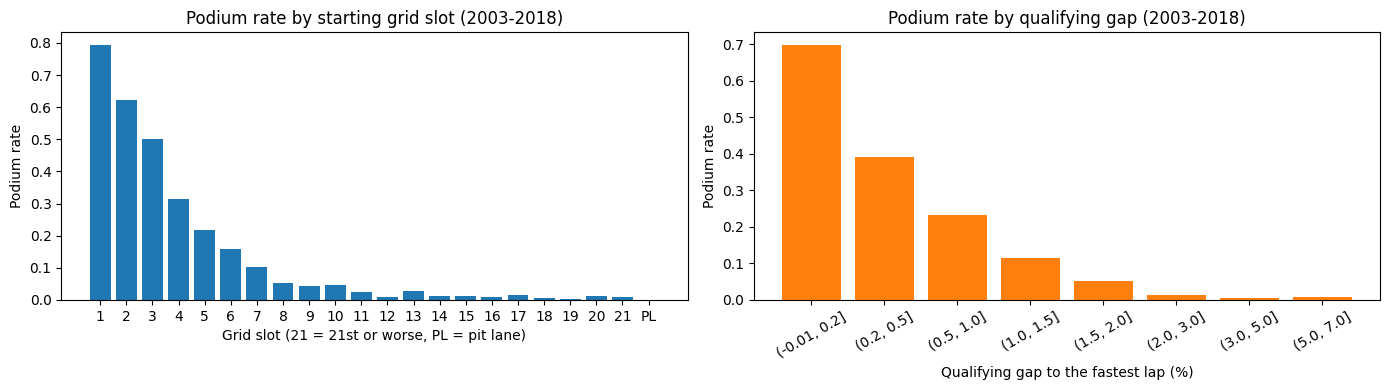

1     0.793
,2     0.622
,3     0.500
,4     0.313
,5     0.217
,6     0.160
,7     0.103
,8     0.053
,9     0.043
,10    0.047


In [26]:
slot = np.where(evidence["pitlane_start"] == 1, "PL", evidence["grid_pos"].clip(upper=21).astype(int).astype(str))
grid_rate = evidence.groupby(slot)[TARGET].agg(["mean", "size"]).reindex([str(i) for i in range(1, 22)] + ["PL"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(grid_rate.index, grid_rate["mean"])
axes[0].set_xlabel("Grid slot (21 = 21st or worse, PL = pit lane)")
axes[0].set_ylabel("Podium rate")
axes[0].set_title("Podium rate by starting grid slot (2003-2018)")

gap_bins = pd.cut(evidence["quali_gap_pct"], [-0.01, 0.2, 0.5, 1, 1.5, 2, 3, 5, 7])
gap_rate = evidence.groupby(gap_bins, observed=True)[TARGET].mean()
axes[1].bar(gap_rate.index.astype(str), gap_rate.values, color="tab:orange")
axes[1].set_xlabel("Qualifying gap to the fastest lap (%)")
axes[1].set_ylabel("Podium rate")
axes[1].set_title("Podium rate by qualifying gap (2003-2018)")
axes[1].tick_params(axis="x", rotation=30)
save_fig("14_fe_grid_and_quali_gap.png")

print(grid_rate.head(10)["mean"].round(3).to_string())

In [27]:
top5 = evidence[evidence["quali_pos"].between(1, 5) & evidence["grid_penalty"].notna()]
print(top5.groupby("grid_penalty")[TARGET].agg(rows="size", podium_rate="mean").round(3))

              rows  podium_rate
,grid_penalty                   
,0.0           1446        0.502
,1.0             54        0.241


The grid is the single strongest signal, and it is non-linear: pole converts ~79% of the time, P3 ~50%, P8 ~5%. The qualifying gap shows the same pattern in a continuous form. Drivers who qualified in the top 5 but started 3+ places back reached the podium about half as often (24% vs 50%), which supports `grid_penalty`.

Next, a single-feature ROC-AUC and Spearman correlation with the target for every candidate. The AUC is folded so that 0.5 means no signal and the direction is shown separately.

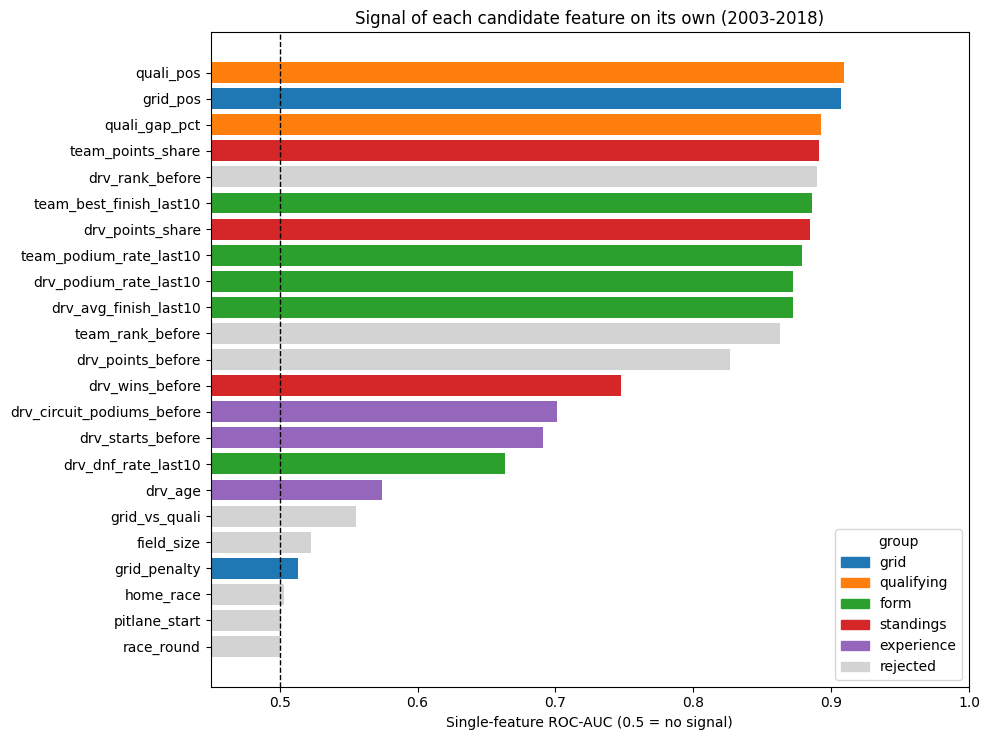

,feature,group,missing_pct,spearman_with_podium,univariate_auc,direction
0,quali_pos,qualifying,0.328,-0.494,0.909,lower -> more podiums
1,grid_pos,grid,0.000,-0.491,0.907,lower -> more podiums
2,quali_gap_pct,qualifying,1.795,-0.475,0.893,lower -> more podiums
3,team_points_share,standings,5.275,0.472,0.891,higher -> more podiums
4,drv_rank_before,rejected,7.336,-0.473,0.890,lower -> more podiums
5,team_best_finish_last10,form,0.531,-0.465,0.886,lower -> more podiums
6,drv_points_share,standings,5.275,0.467,0.885,higher -> more podiums
7,team_podium_rate_last10,form,0.531,0.493,0.879,higher -> more podiums
8,drv_podium_rate_last10,form,1.124,0.511,0.872,higher -> more podiums
9,drv_avg_finish_last10,form,1.124,-0.450,0.872,lower -> more podiums


In [28]:
uni = []
for col in FEATURES + REJECTED:
    ok = evidence[col].notna()
    auc = roc_auc_score(evidence.loc[ok, TARGET], evidence.loc[ok, col])
    group = next((g for g, cols in FEATURE_GROUPS.items() if col in cols), "rejected")
    uni.append({
        "feature": col, "group": group,
        "missing_pct": 100 * (1 - ok.mean()),
        "spearman_with_podium": stats.spearmanr(evidence.loc[ok, col], evidence.loc[ok, TARGET])[0],
        "univariate_auc": max(auc, 1 - auc),
        "direction": "higher -> more podiums" if auc >= 0.5 else "lower -> more podiums",
    })
uni = pd.DataFrame(uni).sort_values("univariate_auc", ascending=False).reset_index(drop=True)

colors = {"grid": "tab:blue", "qualifying": "tab:orange", "form": "tab:green",
          "standings": "tab:red", "experience": "tab:purple", "rejected": "lightgrey"}
plot_uni = uni.sort_values("univariate_auc")
plt.figure(figsize=(10, 7.5))
plt.barh(plot_uni["feature"], plot_uni["univariate_auc"], color=plot_uni["group"].map(colors))
plt.axvline(0.5, color="black", linestyle="--", linewidth=1)
plt.xlim(0.45, 1)
plt.xlabel("Single-feature ROC-AUC (0.5 = no signal)")
plt.title("Signal of each candidate feature on its own (2003-2018)")
plt.legend(handles=[Patch(color=c, label=g) for g, c in colors.items()], title="group", loc="lower right")
save_fig("15_fe_univariate_auc.png")
uni.round(3)

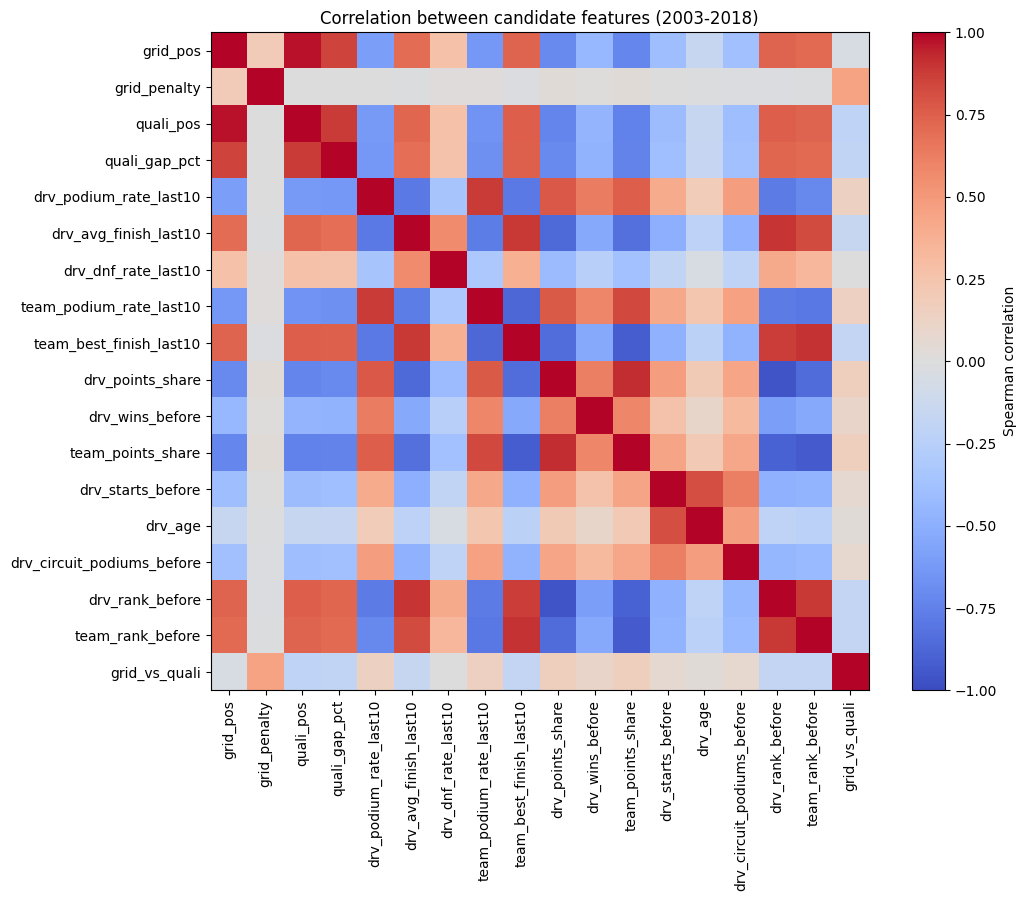

,feature_1,feature_2,rho
2,grid_pos,quali_pos,0.970
177,drv_points_share,drv_rank_before,-0.955
214,team_points_share,team_rank_before,-0.923
173,drv_points_share,team_points_share,0.922
155,team_best_finish_last10,team_points_share,-0.915
160,team_best_finish_last10,team_rank_before,0.900
105,drv_avg_finish_last10,drv_rank_before,0.892
213,team_points_share,drv_rank_before,-0.892


In [29]:
candidates = FEATURES + ["drv_rank_before", "team_rank_before", "grid_vs_quali"]
corr = evidence[candidates].corr(method="spearman")
plt.figure(figsize=(11, 9))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(candidates)), candidates, rotation=90)
plt.yticks(range(len(candidates)), candidates)
plt.title("Correlation between candidate features (2003-2018)")
save_fig("16_fe_feature_correlation.png")

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs = pairs.rename("rho").rename_axis(["feature_1", "feature_2"]).reset_index()
pairs.loc[pairs["rho"].abs().sort_values(ascending=False).index].head(8).round(3)

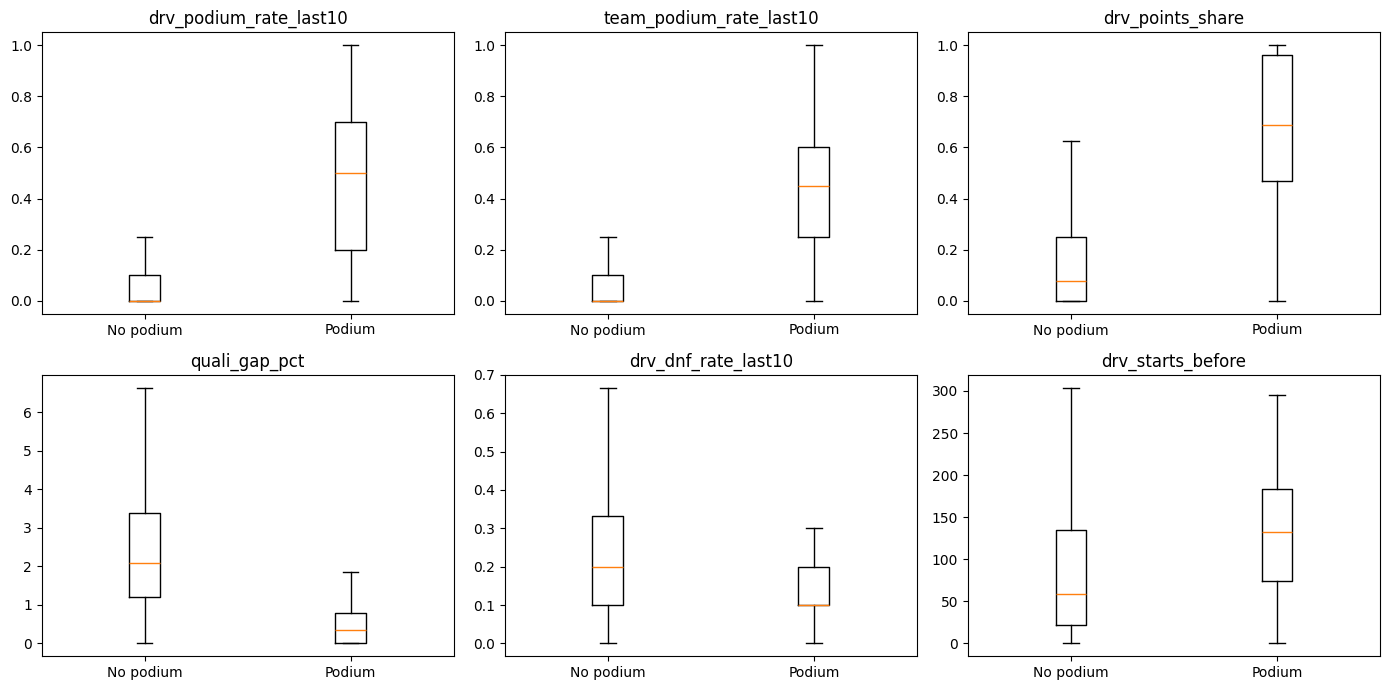

In [30]:
box_cols = ["drv_podium_rate_last10", "team_podium_rate_last10", "drv_points_share",
            "quali_gap_pct", "drv_dnf_rate_last10", "drv_starts_before"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), box_cols):
    data = [evidence.loc[evidence[TARGET] == k, col].dropna() for k in [0, 1]]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks([1, 2], ["No podium", "Podium"])
    ax.set_title(col)
save_fig("17_fe_feature_distributions.png")

In [31]:
leader_by_year = (driver_standings.merge(races[["raceId", "year"]], on="raceId")
                  .groupby("year")["points"].max())
print("Champion's final points in a few seasons (why raw points are not used):")
print(leader_by_year.loc[[2005, 2009, 2010, 2014, 2019, 2023]].to_string())

Champion's final points in a few seasons (why raw points are not used):
,year
,2005    133.0
,2009     95.0
,2010    256.0
,2014    384.0
,2019    413.0
,2023    575.0


### 6.7 Final feature set

| Group | Feature | Why it is valid at the cutoff | Evidence |
|---|---|---|---|
| grid | `grid_pos` | Starting slot is fixed once penalties are applied, before the start | Strongest signal (AUC ≈ 0.91), steep non-linear podium curve |
| grid | `grid_penalty` | Grid and qualifying are both known before the start | Top-5 qualifiers moved back: 24% vs 50% podium rate (and Q1) |
| qualifying | `quali_pos` | Qualifying is over at the cutoff | AUC ≈ 0.91. Differs from grid exactly in the penalty cases |
| qualifying | `quali_gap_pct` | Qualifying lap times are known | AUC ≈ 0.89. Measures pace, not just order |
| form | `drv_podium_rate_last10` | Only the 10 races *before* this one | AUC ≈ 0.87. Window chosen by the experiment in 6.2 |
| form | `drv_avg_finish_last10` | Same | AUC ≈ 0.87 |
| form | `drv_dnf_rate_last10` | Same (DNFs of earlier races) | AUC ≈ 0.66. A reliability signal that Q3 shows varies a lot between teams |
| form | `team_podium_rate_last10` | Team's previous 10 races, computed at team-race level | AUC ≈ 0.88. Car strength regardless of driver |
| form | `team_best_finish_last10` | Same | AUC ≈ 0.89 |
| standings | `drv_points_share` | Standings after the *previous* round | AUC ≈ 0.89. Comparable across points systems |
| standings | `drv_wins_before` | Same | AUC ≈ 0.75 |
| standings | `team_points_share` | Same | AUC ≈ 0.89 |
| experience | `drv_starts_before` | Count of earlier starts | AUC ≈ 0.69. Experienced drivers end up in top cars |
| experience | `drv_age` | Date of birth and race date | Weak on its own (≈ 0.58). Kept as a low-cost context feature |
| experience | `drv_circuit_podiums_before` | Podiums at this circuit in earlier seasons | AUC ≈ 0.70 |

**Rejected candidates:**

- `home_race`: Q2 found no grid-adjusted home effect and its AUC is 0.50.
- `pitlane_start`: about 1% of rows, no signal on its own (AUC 0.50). Already covered because `grid_pos` puts these cars at the back.
- `grid_vs_quali`: exactly `grid_pos − quali_pos`, so it is perfectly collinear with the two features we keep. Replaced by the `grid_penalty` flag.
- `drv_rank_before` and `team_rank_before`: correlation −0.95 / −0.92 with the points shares, and more missing values. They are near-duplicates.
- `drv_points_before` (raw points): the champion scored 95 points in 2009 and 575 in 2023, so raw points mean different things in different seasons.
- `field_size` and `race_round`: these are race-level constants. Every race has exactly three podiums, so they carry no signal by construction (AUC ≈ 0.5).
- `race_year`, `driverId`, `constructorId`, `circuitId`, car `number`: these are identifiers or a calendar trend. With a chronological split the model would have to extrapolate them to unseen seasons and new drivers. The form and standings features capture *how strong* a driver or team is, which is what actually transfers.

Strong correlations remain *between* groups (for example grid vs qualifying 0.97, team form vs team points share ≈ 0.9). This is expected, since they are different views of the same car's pace. It matters for the ablation, because removing one group may cost little when another group carries the same information. That is why the spec also suggests removing grid and qualifying together.

drv_points_share           5.11
,team_points_share          5.11
,quali_gap_pct              1.65
,drv_dnf_rate_last10        0.99
,drv_avg_finish_last10      0.99
,drv_podium_rate_last10     0.99
,team_best_finish_last10    0.47
,team_podium_rate_last10    0.47
,grid_penalty               0.27
,quali_pos                  0.27


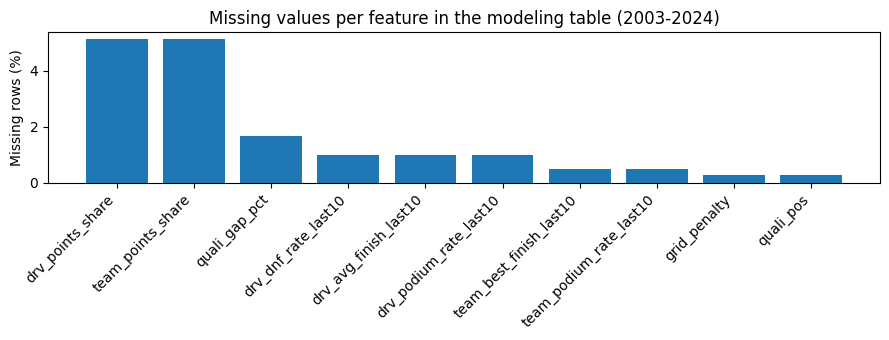

In [32]:
modern = hist[hist["race_year"] >= 2003]
missing = modern[FEATURES].isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]
print(missing.round(2).to_string())

plt.figure(figsize=(9, 3.5))
plt.bar(missing.index, missing.values)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Missing rows (%)")
plt.title("Missing values per feature in the modeling table (2003-2024)")
save_fig("18_fe_missingness.png")

The missing values are not random errors. Each one has a clear reason:

- **Points shares (~5%):** these are exactly the season-opener rows, because there are no standings before round 1.
- **Form (~1%):** the driver's or team's first ever race, so there is no history.
- **`quali_gap_pct` (~1.7%):** the driver has a qualifying position but no lap time (did not set a time, or the time was deleted).
- **`quali_pos` / `grid_penalty` (~0.3%):** there is no qualifying record.

We deliberately **do not impute here**. Imputation is a fitted preprocessing step, so it belongs in Member 3's pipeline and must be fitted on the training split only. Leaving the NaNs in also lets Member 3 run the preprocessing-order experiments.

## 7. Leakage checks

Three kinds of checks:

1. No post-race column is in the feature list.
2. For 300 random rows we recompute the driver form, team form and standings features **from scratch**, using only races with a smaller `race_seq`, and compare them with the vectorised values.
3. A driver's first race has no form, and season openers have no standings.

In [33]:
POST_RACE = {"positionOrder", "position", "positionText", "points", "laps", "time", "milliseconds", "fastestLap",
             "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status", "finished", "dnf"}
assert not POST_RACE & set(FEATURES)

rng = np.random.default_rng(7)
sample_idx = rng.choice(hist.index[hist["race_year"] >= 2003], size=300, replace=False)

for i in sample_idx:
    row = hist.loc[i]
    earlier = hist[(hist["driverId"] == row["driverId"]) & (hist["race_seq"] < row["race_seq"])]
    earlier = earlier.sort_values("race_seq").tail(WINDOW)
    expected = earlier["podium"].mean() if len(earlier) else np.nan
    assert np.isclose(expected, row["drv_podium_rate_last10"], equal_nan=True), i

    team_earlier = team_race[(team_race["constructorId"] == row["constructorId"]) &
                             (team_race["race_seq"] < row["race_seq"])].tail(WINDOW)
    expected_team = team_earlier["team_podiums"].sum() / team_earlier["team_cars"].sum() if len(team_earlier) else np.nan
    assert np.isclose(expected_team, row["team_podium_rate_last10"], equal_nan=True), i

    if pd.notna(row["prev_raceId"]):
        prev = driver_standings[(driver_standings["raceId"] == row["prev_raceId"]) &
                                (driver_standings["driverId"] == row["driverId"])]
        expected_pts = prev["points"].iloc[0] if len(prev) else 0
        assert np.isclose(expected_pts, row["drv_points_before"]), i

first_races = hist.sort_values("race_seq").groupby("driverId").head(1)
assert first_races["drv_podium_rate_last10"].isna().all()
assert first_races["drv_starts_before"].eq(0).all()
assert hist.loc[hist["prev_raceId"].isna(), "drv_points_share"].isna().all()
assert uni.loc[uni["feature"].isin(FEATURES), "univariate_auc"].max() < 0.95
print("All leakage checks passed (300 rows recomputed from scratch).")

All leakage checks passed (300 rows recomputed from scratch).


The last assert is a sanity check rather than a proof: if any single pre-race feature separated podiums almost perfectly (AUC > 0.95), that would usually mean the race result had slipped in somewhere.

## 8. Export for Member 3

In [34]:
modeling_table = (
    hist.loc[hist["race_year"].between(2003, 2024), ID_COLS + FEATURES + [TARGET]]
    .sort_values(["race_date", "raceId", "driverId"])
    .reset_index(drop=True)
)
full_history = hist[ID_COLS + FEATURES + [TARGET]].sort_values(["race_date", "raceId", "driverId"]).reset_index(drop=True)

assert not modeling_table.duplicated(["raceId", "driverId"]).any()
assert modeling_table[TARGET].isin([0, 1]).all()
assert modeling_table[ID_COLS].notna().all().all()

modeling_table.to_csv(FEATURE_DIR / "modeling_table.csv", index=False)
full_history.to_csv(FEATURE_DIR / "driver_race_features_full_history.csv", index=False)
uni.to_csv(REPORT_DIR / "member2_feature_evidence.csv", index=False)

ablation_drop = {group: list(cols) for group, cols in FEATURE_GROUPS.items()}
ablation_drop["qualifying"] = ablation_drop["qualifying"] + ["grid_penalty"]
ablation_drop["grid_and_qualifying"] = FEATURE_GROUPS["grid"] + FEATURE_GROUPS["qualifying"]

spec = {
    "target": TARGET,
    "id_columns": ID_COLS,
    "features": FEATURES,
    "feature_groups": FEATURE_GROUPS,
    "ablation_drop": ablation_drop,
    "binary_features": ["grid_penalty"],
    "modeling_years": [2003, 2024],
    "evidence_years": list(EVIDENCE_YEARS),
}
(FEATURE_DIR / "feature_spec.json").write_text(json.dumps(spec, indent=2), encoding="utf-8")

print("modeling_table.csv:", modeling_table.shape, "| podium rate:", round(modeling_table[TARGET].mean(), 3))
print("Races:", modeling_table["raceId"].nunique(), "| seasons:", modeling_table["race_year"].min(), "-", modeling_table["race_year"].max())
modeling_table.head()

modeling_table.csv: (8966, 23) | podium rate: 0.143
,Races: 428 | seasons: 2003 - 2024


,raceId,driverId,constructorId,circuitId,race_year,race_round,race_date,grid_pos,grid_penalty,quali_pos,quali_gap_pct,drv_podium_rate_last10,drv_avg_finish_last10,drv_dnf_rate_last10,team_podium_rate_last10,team_best_finish_last10,drv_points_share,drv_wins_before,team_points_share,drv_starts_before,drv_age,drv_circuit_podiums_before,podium
0,108,2,15,1,2003,1,2003-03-09,7,0.0,7.0,1.480963,0.0,8.3,0.0,0.0,7.7,NaN,0.0,NaN,50,25.828884,0.0,0
1,108,4,4,1,2003,1,2003-03-09,10,0.0,10.0,2.013238,0.0,16.1,0.5,0.0,8.4,NaN,0.0,NaN,17,21.609856,0.0,0
2,108,8,1,1,2003,1,2003-03-09,15,0.0,15.0,2.634990,0.3,8.9,0.5,0.3,4.3,NaN,0.0,NaN,34,23.392197,1.0,1
3,108,14,1,1,2003,1,2003-03-09,11,0.0,11.0,2.216283,0.3,7.8,0.2,0.3,4.3,NaN,0.0,NaN,141,31.950719,3.0,1
4,108,15,4,1,2003,1,2003-03-09,12,0.0,12.0,2.251844,0.0,10.5,0.5,0.0,8.4,NaN,0.0,NaN,97,28.654346,0.0,0


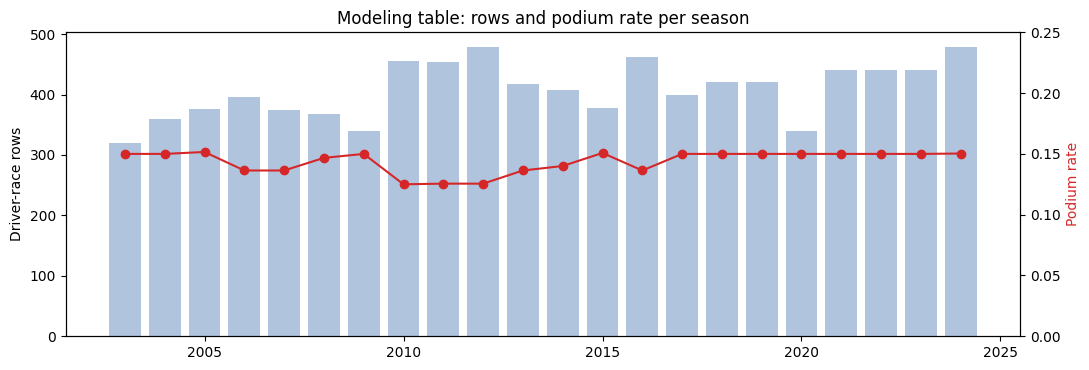

In [35]:
per_season = modeling_table.groupby("race_year").agg(rows=(TARGET, "size"), podium_rate=(TARGET, "mean"))
fig, ax1 = plt.subplots(figsize=(11, 3.8))
ax1.bar(per_season.index, per_season["rows"], color="lightsteelblue")
ax1.set_ylabel("Driver-race rows")
ax2 = ax1.twinx()
ax2.plot(per_season.index, per_season["podium_rate"], color="tab:red", marker="o")
ax2.set_ylabel("Podium rate", color="tab:red")
ax2.set_ylim(0, 0.25)
plt.title("Modeling table: rows and podium rate per season")
save_fig("19_fe_modeling_table_balance.png")

## 9. Notes for Member 3

- **Load:** `data/features/modeling_table.csv` together with `data/features/feature_spec.json` (feature list, groups and the exact columns to drop for each ablation). Use `spec["features"]` as X and `spec["target"]` as y, so every model sees the same rows and the same features.
- **Class balance:** about 14% positives (three podiums per race), so PR-AUC and F1 matter more than accuracy.
- **Split:** the rows are time-ordered, so the split should be chronological by season. A random split would put races from the same season (and the same car) in both train and test. Our feature evidence only used 2003–2018, so something like train 2003–2018 / validation 2019–2021 / test 2022–2024 keeps the test seasons completely untouched. The final choice is yours.
- **Missing values:** left as NaN on purpose (see 6.7). Fit the imputer on the training split only. Adding missing-value indicators is reasonable for the points shares, because "missing" there means "season opener".
- **Scaling:** all features are numeric. `grid_penalty` is a 0/1 flag. Counts like `drv_starts_before` are skewed, which is worth considering for logistic regression and the neural network.
- **Ablation:** `ablation_drop` lists the columns to remove for each group. `grid_penalty` is also dropped in the qualifying ablation because it is derived from qualifying position. Grid and qualifying are 0.97 correlated, so `grid_and_qualifying` (both removed together) is the more informative experiment.
- **Known limitations:** constructor renames reset the team form (for example Toro Rosso → AlphaTauri). Standings are undefined at round 1. Sprint-weekend formats changed in 2021–2023. The 2022 regulation change makes the last seasons a genuinely different era.